<img src="https://github.com/hernancontigiani/ceia_memorias_especializacion/raw/master/Figures/logoFIUBA.jpg" width="500" align="center">


# Procesamiento de lenguaje natural
## Modelo de lenguaje con tokenización por caracteres

### Consigna
- Seleccionar un corpus de texto sobre el cual entrenar el modelo de lenguaje.
- Realizar el pre-procesamiento adecuado para tokenizar el corpus, estructurar el dataset y separar entre datos de entrenamiento y validación.
- Proponer arquitecturas de redes neuronales basadas en unidades recurrentes para implementar un modelo de lenguaje.
- Con el o los modelos que consideren adecuados, generar nuevas secuencias a partir de secuencias de contexto con las estrategias de greedy search y beam search determístico y estocástico. En este último caso observar el efecto de la temperatura en la generación de secuencias.


### Sugerencias
- Durante el entrenamiento, guiarse por el descenso de la perplejidad en los datos de validación para finalizar el entrenamiento. Para ello se provee un callback.
- Explorar utilizar SimpleRNN (celda de Elman), LSTM y GRU.
- rmsprop es el optimizador recomendado para la buena convergencia. No obstante se pueden explorar otros.


In [ ]:
import random
import io
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

from tensorflow import keras
from tensorflow.keras import layers
from keras.utils import to_categorical
from keras.models import Sequential
from keras.layers import Dense, LSTM, Embedding, Dropout
from tensorflow.keras.losses import SparseCategoricalCrossentropy

### Datos

In [ ]:
# descargar de textos.info
import urllib.request

# Para leer y parsear el texto en HTML de wikipedia
import bs4 as bs

In [ ]:
raw_html = urllib.request.urlopen('https://www.textos.info/julio-verne/la-vuelta-al-mundo-en-80-dias/ebook')
raw_html = raw_html.read()

# Parsear artículo, 'lxml' es el parser a utilizar
article_html = bs.BeautifulSoup(raw_html, 'lxml')

# Encontrar todos los párrafos del HTML (bajo el tag <p>)
# y tenerlos disponible como lista
article_paragraphs = article_html.find_all('p')

article_text = ''

for para in article_paragraphs:
    article_text += para.text + ' '

# pasar todo el texto a minúscula
article_text = article_text.lower()

In [ ]:
# en article text se encuentra el texto de todo el libro
article_text[:1000]

' en el año 1872, la casa número 7 de saville-row, burlington gardens \n—donde murió sheridan en 1814— estaba habitada por phileas fogg, quien a\n pesar de que parecía haber tomado el partido de no hacer nada que \npudiese llamar la atención, era uno de los miembros más notables y \nsingulares del reformclub de londres. por consiguiente, phileas fogg, personaje enigmático y del cual sólo \nse sabía que era un hombre muy galante y de los más cumplidos gentlemen \nde la alta sociedad inglesa, sucedía a uno de los más grandes oradores \nque honran a inglaterra. decíase que se daba un aire a lo byron —su cabeza, se entiende, \nporque, en cuanto a los pies, no tenía defecto alguno—, pero a un byron \nde bigote y pastillas, a un byron impasible, que hubiera vivido mil años\n sin envejecer. phileas fogg, era inglés de pura cepa; pero quizás no había nacido en\n londres. jamás se le había visto en la bolsa ni en el banco, ni en \nninguno de los despachos mercantiles de la city. ni las dársenas

### Elegir el tamaño del contexto

En este caso, como el modelo de lenguaje es por caracteres, todo un gran corpus
de texto puede ser considerado un documento en sí mismo y el tamaño de contexto
puede ser elegido con más libertad en comparación a un modelo de lenguaje tokenizado por palabras y dividido en documentos más acotados.

In [ ]:
# seleccionamos el tamaño de contexto
max_context_size = 100

In [ ]:
# Usaremos las utilidades de procesamiento de textos y secuencias de Keras
from tensorflow.keras.utils import pad_sequences # se utilizará para padding

In [ ]:
# en este caso el vocabulario es el conjunto único de caracteres que existe en todo el texto
# se ordena para que el mapeo sea reproducible entre sesiones
chars_vocab = sorted(set(article_text))

In [ ]:
# la longitud de vocabulario de caracteres es:
len(chars_vocab)

67

In [ ]:
# Construimos los dicionarios que asignan índices a caracteres y viceversa.
# El diccionario `char2idx` servirá como tokenizador.
# Los índices empiezan en 1: el 0 queda reservado para el padding
char2idx = {k: v for v,k in enumerate(chars_vocab, start=1)}
idx2char = {v: k for k,v in char2idx.items()}

###  Tokenizar

In [ ]:
# tokenizamos el texto completo
tokenized_text = [char2idx[ch] for ch in article_text]

In [ ]:
tokenized_text[:1000]

[3,
 32,
 41,
 3,
 32,
 39,
 3,
 28,
 63,
 42,
 3,
 14,
 21,
 20,
 15,
 9,
 3,
 39,
 28,
 3,
 30,
 28,
 46,
 28,
 3,
 41,
 65,
 40,
 32,
 45,
 42,
 3,
 20,
 3,
 31,
 32,
 3,
 46,
 28,
 49,
 36,
 39,
 39,
 32,
 10,
 45,
 42,
 50,
 9,
 3,
 29,
 48,
 45,
 39,
 36,
 41,
 34,
 47,
 42,
 41,
 3,
 34,
 28,
 45,
 31,
 32,
 41,
 46,
 3,
 2,
 67,
 31,
 42,
 41,
 31,
 32,
 3,
 40,
 48,
 45,
 36,
 64,
 3,
 46,
 35,
 32,
 45,
 36,
 31,
 28,
 41,
 3,
 32,
 41,
 3,
 14,
 21,
 14,
 17,
 67,
 3,
 32,
 46,
 47,
 28,
 29,
 28,
 3,
 35,
 28,
 29,
 36,
 47,
 28,
 31,
 28,
 3,
 43,
 42,
 45,
 3,
 43,
 35,
 36,
 39,
 32,
 28,
 46,
 3,
 33,
 42,
 34,
 34,
 9,
 3,
 44,
 48,
 36,
 32,
 41,
 3,
 28,
 2,
 3,
 43,
 32,
 46,
 28,
 45,
 3,
 31,
 32,
 3,
 44,
 48,
 32,
 3,
 43,
 28,
 45,
 32,
 30,
 62,
 28,
 3,
 35,
 28,
 29,
 32,
 45,
 3,
 47,
 42,
 40,
 28,
 31,
 42,
 3,
 32,
 39,
 3,
 43,
 28,
 45,
 47,
 36,
 31,
 42,
 3,
 31,
 32,
 3,
 41,
 42,
 3,
 35,
 28,
 30,
 32,
 45,
 3,
 41,
 28,
 31,
 28,
 3,
 44,
 48,
 3

### Organizando y estructurando el dataset

In [ ]:
# separaremos el dataset entre entrenamiento y validación.
# `p_val` será la proporción del corpus que se reservará para validación
# `num_val` es la cantidad de secuencias de tamaño `max_context_size` que se usará en validación
p_val = 0.1
num_val = int(np.ceil(len(tokenized_text)*p_val/max_context_size))

In [ ]:
# separamos la porción de texto utilizada en entrenamiento de la de validación.
train_text = tokenized_text[:-num_val*max_context_size]
val_text = tokenized_text[-num_val*max_context_size:]

In [ ]:
tokenized_sentences_val = [val_text[init*max_context_size:(init+1)*max_context_size] for init in range(num_val)]

In [ ]:
tokenized_sentences_train = [train_text[init:init+max_context_size] for init in range(len(train_text)-max_context_size+1)]

In [ ]:
X = np.array(tokenized_sentences_train[:-1])
y = np.array(tokenized_sentences_train[1:])

Nótese que estamos estructurando el problema de aprendizaje como *many-to-many*:

Entrada: secuencia de tokens [$x_0$, $x_1$, ..., $x_N$]

Target: secuencia de tokens [$x_1$, $x_2$, ..., $x_{N+1}$]

De manera que la red tiene que aprender que su salida deben ser los tokens desplazados en una posición y un nuevo token predicho (el N+1).

La ventaja de estructurar el aprendizaje de esta manera es que para cada token de target se propaga una señal de gradiente por el grafo de cómputo recurrente, que es mejor que estructurar el problema como *many-to-one* en donde sólo una señal de gradiente se propaga.

En este punto tenemos en la variable `tokenized_sentences` los versos tokenizados. Vamos a quedarnos con un conjunto de validación que utilizaremos para medir la calidad de la generación de secuencias con la métrica de Perplejidad.

In [ ]:
X.shape

(355829, 100)

In [ ]:
X[0,:10]

array([ 3, 32, 41,  3, 32, 39,  3, 28, 63, 42])

In [ ]:
y[0,:10]

array([32, 41,  3, 32, 39,  3, 28, 63, 42,  3])

In [ ]:
# +1 por el índice 0 reservado para el padding
vocab_size = len(chars_vocab) + 1

# Definiendo el modelo

In [ ]:
from keras.layers import Input, TimeDistributed, CategoryEncoding, SimpleRNN, Dense
from keras.models import Model, Sequential

El modelo que se propone como ejemplo consume los índices de los tokens y los transforma en vectores OHE (en este caso no entrenamos una capa de embedding para caracteres). Esa transformación se logra combinando las capas `CategoryEncoding` que transforma a índices a vectores OHE y `TimeDistributed` que aplica la capa a lo largo de la dimensión "temporal" de la secuencia.

In [ ]:
model = Sequential()

model.add(TimeDistributed(CategoryEncoding(num_tokens=vocab_size, output_mode = "one_hot"),input_shape=(None,1)))
model.add(SimpleRNN(200, return_sequences=True, dropout=0.1, recurrent_dropout=0.1 ))
model.add(Dense(vocab_size, activation='softmax'))
model.compile(loss='sparse_categorical_crossentropy', optimizer='rmsprop')

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/wrapper.py:27: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ time_distributed_3              │ (None, None, 68)       │             0 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, None, 200)      │        53,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, None, 68)       │        13,668 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 67,468 (263.55 KB)

 Trainable params: 67,468 (263.55 KB)

 Non-trainable params: 0 (0.00 B)


### Definir el modelo

Dado que por el momento no hay implementaciones adecuadas de la perplejidad que puedan operar en tiempo de entrenamiento, armaremos un Callback *ad-hoc* que la calcule en cada epoch.

**Nota**: un Callback es una rutina gatillada por algún evento, son muy útiles para relevar datos en diferentes momentos del desarrollo del modelo. En este caso queremos hacer un cálculo cada vez que termina una epoch de entrenamiento.

In [ ]:
class PplCallback(keras.callbacks.Callback):

    '''
    Este callback es una solución ad-hoc para calcular al final de cada epoch de
    entrenamiento la métrica de Perplejidad sobre un conjunto de datos de validación.
    La perplejidad es una métrica cuantitativa para evaluar la calidad de la generación de secuencias.
    Además implementa la finalización del entrenamiento (Early Stopping)
    si la perplejidad no mejora después de `patience` epochs.
    El mejor modelo se guarda en `path`.
    '''

    def __init__(self, val_data, history_ppl, path, patience=5):
      # El callback lo inicializamos con secuencias de validación sobre las cuales
      # mediremos la perplejidad
      self.val_data = val_data
      self.history_ppl = history_ppl
      self.path = path

      self.target = []
      self.padded = []

      count = 0
      self.info = []
      self.min_score = np.inf
      self.patience_counter = 0
      self.patience = patience

      # nos movemos en todas las secuencias de los datos de validación
      for seq in self.val_data:

        len_seq = len(seq)
        # armamos todas las subsecuencias
        subseq = [seq[:i] for i in range(1,len_seq)]
        self.target.extend([seq[i] for i in range(1,len_seq)])

        if len(subseq)!=0:

          self.padded.append(pad_sequences(subseq, maxlen=max_context_size, padding='pre'))

          # cada secuencia aporta len_seq-1 subsecuencias (y targets)
          self.info.append((count,count+len_seq-1))
          count += len_seq-1

      self.padded = np.vstack(self.padded)


    def on_epoch_end(self, epoch, logs=None):

        # en `scores` iremos guardando la perplejidad de cada secuencia
        scores = []

        predictions = self.model.predict(self.padded,verbose=0)

        # para cada secuencia de validación
        for start,end in self.info:

          # en `probs` iremos guardando las probabilidades de los términos target
          probs = [predictions[idx_seq,-1,idx_vocab] for idx_seq, idx_vocab in zip(range(start,end),self.target[start:end])]

          # calculamos la perplejidad por medio de logaritmos
          scores.append(np.exp(-np.sum(np.log(probs))/(end-start)))

        # promediamos todos los scores e imprimimos el valor promedio
        current_score = np.mean(scores)
        self.history_ppl.append(current_score)
        print(f'\n mean perplexity: {current_score} \n')

        # chequeamos si tenemos que detener el entrenamiento
        if current_score < self.min_score:
          self.min_score = current_score
          self.model.save(self.path)
          print("Saved new model!")
          self.patience_counter = 0
        else:
          self.patience_counter += 1
          if self.patience_counter == self.patience:
            print("Stopping training...")
            self.model.stop_training = True


### Entrenamiento

In [ ]:
# fiteamos, nótese el agregado del callback con su inicialización. El batch_size lo podemos seleccionar a mano
# en general, lo mejor es escoger el batch más grande posible que minimice el tiempo de cada época.
# En la variable `history_ppl` se guardarán los valores de perplejidad para cada época.
history_ppl = []
hist = model.fit(X, y, epochs=20, callbacks=[PplCallback(tokenized_sentences_val, history_ppl, 'SimpleRNN.keras')], batch_size=256)

Epoch 1/20
1390/1390 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 2.4583
 mean perplexity: 6.49528694152832 

Saved new model!
1390/1390 ━━━━━━━━━━━━━━━━━━━━ 38s 21ms/step - loss: 2.2192
Epoch 2/20
1389/1390 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 1.9514
 mean perplexity: 5.63302755355835 

Saved new model!
1390/1390 ━━━━━━━━━━━━━━━━━━━━ 19s 14ms/step - loss: 1.9169
Epoch 3/20
1387/1390 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 1.8435
 mean perplexity: 5.244494438171387 

Saved new model!
1390/1390 ━━━━━━━━━━━━━━━━━━━━ 19s 14ms/step - loss: 1.8283
Epoch 4/20
1389/1390 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 1.7929
 mean perplexity: 5.058082580566406 

Saved new model!
1390/1390 ━━━━━━━━━━━━━━━━━━━━ 19s 14ms/step - loss: 1.7846
Epoch 5/20
1385/1390 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 1.7638
 mean perplexity: 4.92570686340332 

Saved new model!
1390/1390 ━━━━━━━━━━━━━━━━━━━━ 19s 14ms/step - loss: 1.7584
Epoch 6/20
1386/1390 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 1.7445
 mean perplex

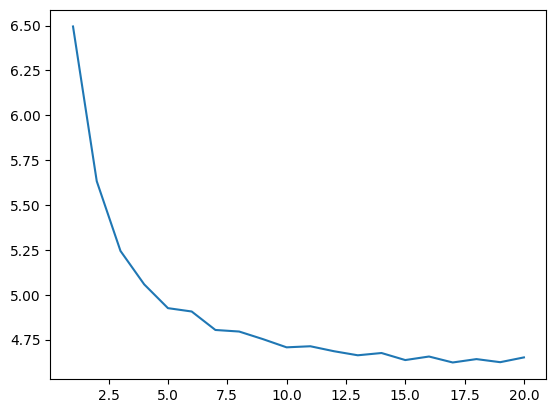

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Entrenamiento
epoch_count = range(1, len(history_ppl) + 1)
sns.lineplot(x=epoch_count,  y=history_ppl)
plt.show()

### Comparación de arquitecturas: SimpleRNN vs GRU vs LSTM

Se entrenan GRU y LSTM con la misma configuración que la SimpleRNN, salvo que sin `recurrent_dropout` (que impide usar los kernels optimizados de GPU y vuelve el entrenamiento muy lento).

In [ ]:
from keras.layers import GRU

histories = {'SimpleRNN': history_ppl}

for name, rnn_layer in {'GRU': GRU, 'LSTM': LSTM}.items():
    model_rnn = Sequential([
        Input(shape=(None,1)),
        TimeDistributed(CategoryEncoding(num_tokens=vocab_size, output_mode="one_hot")),
        rnn_layer(200, return_sequences=True, dropout=0.1),
        Dense(vocab_size, activation='softmax')])
    model_rnn.compile(loss='sparse_categorical_crossentropy', optimizer='rmsprop')
    histories[name] = []
    model_rnn.fit(X, y, epochs=20, callbacks=[PplCallback(tokenized_sentences_val, histories[name], f'{name}.keras')], batch_size=256)

Epoch 1/20
1386/1390 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 2.5268
 mean perplexity: 6.440749168395996 

Saved new model!
1390/1390 ━━━━━━━━━━━━━━━━━━━━ 27s 17ms/step - loss: 2.2344
Epoch 2/20
1386/1390 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 1.8671
 mean perplexity: 5.188072204589844 

Saved new model!
1390/1390 ━━━━━━━━━━━━━━━━━━━━ 21s 15ms/step - loss: 1.8047
Epoch 3/20
1387/1390 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 1.6625
 mean perplexity: 4.740893840789795 

Saved new model!
1390/1390 ━━━━━━━━━━━━━━━━━━━━ 21s 15ms/step - loss: 1.6311
Epoch 4/20
1386/1390 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 1.5540
 mean perplexity: 4.550992012023926 

Saved new model!
1390/1390 ━━━━━━━━━━━━━━━━━━━━ 21s 15ms/step - loss: 1.5367
Epoch 5/20
1386/1390 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 1.4897
 mean perplexity: 4.429346084594727 

Saved new model!
1390/1390 ━━━━━━━━━━━━━━━━━━━━ 21s 15ms/step - loss: 1.4772
Epoch 6/20
1386/1390 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 1.4434
 mean

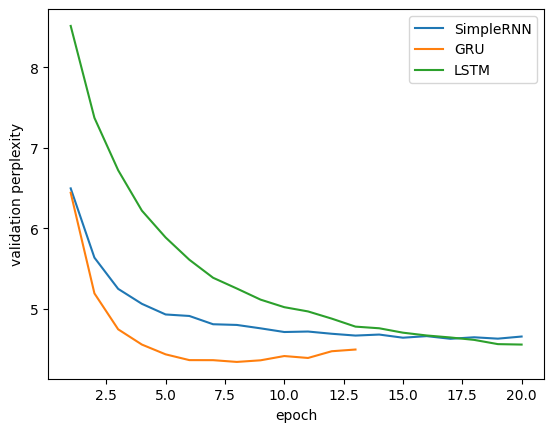

{'SimpleRNN': np.float32(4.623), 'GRU': np.float32(4.335), 'LSTM': np.float32(4.551)} -> best: GRU


In [ ]:
for name, ppl in histories.items():
    sns.lineplot(x=range(1, len(ppl) + 1), y=ppl, label=name)
plt.xlabel('epoch')
plt.ylabel('validation perplexity')
plt.show()

best_name = min(histories, key=lambda name: min(histories[name]))
print({name: round(min(ppl), 3) for name, ppl in histories.items()}, '-> best:', best_name)

In [ ]:
# Cargamos el mejor modelo guardado del entrenamiento para hacer inferencia
model = keras.models.load_model(f'{best_name}.keras')


### Predicción del próximo caracter

In [ ]:
# Se puede usar gradio para probar el modelo
# Gradio es una herramienta muy útil para crear interfaces para ensayar modelos
# https://gradio.app/

!pip install -q gradio

In [ ]:
import gradio as gr

def model_response(human_text):

    # Encodeamos
    encoded = [char2idx[ch] for ch in human_text.lower() ]
    # Si tienen distinto largo
    encoded = pad_sequences([encoded], maxlen=max_context_size, padding='pre')

    # Predicción softmax
    y_hat = np.argmax(model.predict(encoded)[0,-1,:])


    # Debemos buscar en el vocabulario el caracter
    # que corresopnde al indice (y_hat) predicho por le modelo
    out_word = ''
    out_word = idx2char[y_hat]

    # Agrego la palabra a la frase predicha
    return human_text + out_word

iface = gr.Interface(
    fn=model_response,
    inputs=["textbox"],
    outputs="text")

iface.launch(debug=True)

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://20afd50cbb08a32268.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://20afd50cbb08a32268.gradio.live


### Generación de secuencias

In [ ]:
def generate_seq(model, seed_text, max_length, n_words):
    """
        Exec model sequence prediction

        Args:
            model (keras): modelo entrenado
            seed_text (string): texto de entrada (input_seq)
            max_length (int): máxima longitud de la sequencia de entrada
            n_words (int): números de caracteres a agregar a la sequencia de entrada
        returns:
            output_text (string): sentencia con las "n_words" agregadas
    """
    output_text = seed_text
	# generate a fixed number of words
    for _ in range(n_words):
		# Encodeamos
        encoded = [char2idx[ch] for ch in output_text.lower() ]
		# Si tienen distinto largo
        encoded = pad_sequences([encoded], maxlen=max_length, padding='pre')

		# Predicción softmax
        y_hat = np.argmax(model.predict(encoded,verbose=0)[0,-1,:])
		# Vamos concatenando las predicciones
        out_word = ''

        out_word = idx2char[y_hat]

		# Agrego las palabras a la frase predicha
        output_text += out_word
    return output_text

In [ ]:
input_text='habia una vez'

generate_seq(model, input_text, max_length=max_context_size, n_words=30)

'habia una vez en cuanto a la presencia de l'

###  Beam search y muestreo aleatorio

In [ ]:
# funcionalidades para hacer encoding y decoding

def encode(text,max_length=max_context_size):

    encoded = [char2idx[ch] for ch in text]
    encoded = pad_sequences([encoded], maxlen=max_length, padding='pre')

    return encoded

def decode(seq):
    return ''.join([idx2char[ch] for ch in seq])

In [ ]:
from scipy.special import softmax

# función que selecciona candidatos para el beam search
def select_candidates(pred,num_beams,vocab_size,history_probs,history_tokens,temp,mode):

  # colectar todas las probabilidades para la siguiente búsqueda
  pred_large = []

  for idx,pp in enumerate(pred):
    pred_large.extend(np.log(pp+1E-10)+history_probs[idx])

  pred_large = np.array(pred_large)

  # criterio de selección
  if mode == 'det':
    idx_select = np.argsort(pred_large)[::-1][:num_beams] # beam search determinista
  elif mode == 'sto':
    idx_select = np.random.choice(np.arange(pred_large.shape[0]), num_beams, p=softmax(pred_large/temp)) # beam search con muestreo aleatorio
  else:
    raise ValueError(f'Wrong selection mode. {mode} was given. det and sto are supported.')

  # traducir a índices de token en el vocabulario
  new_history_tokens = np.concatenate((np.array(history_tokens)[idx_select//vocab_size],
                        np.array([idx_select%vocab_size]).T),
                      axis=1)

  # devolver el producto de las probabilidades (log) y la secuencia de tokens seleccionados
  return pred_large[idx_select.astype(int)], new_history_tokens.astype(int)


def beam_search(model,num_beams,num_words,input,temp=1,mode='det'):

    # first iteration

    # encode
    encoded = encode(input)

    # first prediction
    y_hat = model.predict(encoded,verbose=0)[0,-1,:]

    # get vocabulary size
    vocab_size = y_hat.shape[0]

    # initialize history
    history_probs = [0]*num_beams
    history_tokens = [encoded[0]]*num_beams

    # select num_beams candidates
    history_probs, history_tokens = select_candidates([y_hat],
                                        num_beams,
                                        vocab_size,
                                        history_probs,
                                        history_tokens,
                                        temp,
                                        mode)

    # beam search loop
    for i in range(num_words-1):

      preds = []

      for hist in history_tokens:

        # actualizar secuencia de tokens
        input_update = np.array([hist[i+1:]]).copy()

        # predicción
        y_hat = model.predict(input_update,verbose=0)[0,-1,:]

        preds.append(y_hat)

      history_probs, history_tokens = select_candidates(preds,
                                                        num_beams,
                                                        vocab_size,
                                                        history_probs,
                                                        history_tokens,
                                                        temp,
                                                        mode)

    return history_tokens[:,-(len(input)+num_words):]

In [ ]:
# predicción con beam search
salidas = beam_search(model,num_beams=10,num_words=20,input="habia una vez")

In [ ]:
salidas[0]

array([35, 28, 29, 36, 28,  3, 48, 41, 28,  3, 49, 32, 53,  3, 32, 41,  3,
       30, 48, 28, 41, 47, 42,  3, 28,  3, 43, 36, 30, 28, 43, 42, 45])

In [ ]:
# veamos las salidas
decode(salidas[0])

'habia una vez en cuanto a picapor'

In [ ]:
seed = 'habia una vez'
n_chars = 256

print('greedy:', generate_seq(model, seed, max_context_size, n_chars))
print('beam det:', decode(beam_search(model, 10, n_chars, seed)[0]))
for temp in (0.2, 0.5, 1, 2):
    print(f'beam sto T={temp}:', decode(beam_search(model, 10, n_chars, seed, temp=temp, mode='sto')[0]))

greedy: habia una vez en cuanto a la presencia de la 
compañía de la pagoda de la compañía peninsular en el momento en que se había recibido de la mañana, el tren se había después de haber sido estaba presentarse con el sueño de la estación de la pagoda de la compañía peninsul
beam det: habia una vez en cuanto a mistress aouida, picaporte se habían comprendido a mistress aouida, picaporte se habían comprendido a mistress aouida, picaporte se habían comprendido a mistress aouida, picaporte se habían comprendido a mistress aouida, picaporte se había rec
beam sto T=0.2: habia una vez en el momento en que se había recibido de la mañana, el tren se había recibido de la estación de los cuales se habían sido estaba después de haber sido estaba encontrado con las calles de la mañana, se había recibido de la mañana, el tren se había recibid
beam sto T=0.5: habia una vez en el momento en que el vapor de los cuales estaban encontrados por las calles de la mañana, y por último, entre las cuales se

### Conclusiones

**Arquitecturas**:
- La GRU es la mejor, luego sigue la LSTM y la SimpleRNN es la peor.
- La GRU converge más rápido, pero luego sobreajusta. La LSTM aprende más lento y seguía mejorando, por lo que con más épocas podría alcanzar a la GRU.
- Las diferencias son pequeñas.

**Generación** (modelo GRU, el mejor):
- *Greedy* y *beam search determinístico* dan texto con buena ortografía pero repetitivo, con bucles, porque siempre eligen lo más probable.
- *Beam search estocástico*: la temperatura balancea coherencia y diversidad.
  - T=0.2: casi determinístico, repite frases.
  - T=0.5: un equilibrio, texto más variado.
  - T=1: aún más variado, con algunas frases sin sentido.
  - T=2: aparecen palabras inventadas y se pierde por completo la coherencia.

**En general**: el modelo aprende ortografía y sintaxis local, pero no mantiene coherencia a largo plazo.